# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Cancer Prediction Dataset](https://www.kaggle.com/datasets/rudradahikar/cancer-dataset-prediction)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('cancer.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62


## last Five row

In [4]:
df.tail()

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
49995,PT0049995,80,Male,Pakistan,2023,2.3,7.5,2.8,3.8,2.9,Leukemia,Stage 0,71463.70,1.0,3.63
49996,PT0049996,40,Female,USA,2018,6.4,3.5,2.9,9.0,9.8,Colon,Stage I,49619.66,0.4,6.03
49997,PT0049997,74,Male,Pakistan,2015,6.2,1.6,8.7,4.7,4.0,Breast,Stage 0,5338.25,2.7,6.02
49998,PT0049998,21,Male,Brazil,2018,4.0,6.5,7.6,8.6,8.1,Liver,Stage IV,45100.47,7.5,6.54
49999,PT0049999,22,Male,Pakistan,2023,5.1,9.8,3.2,0.0,0.7,Liver,Stage 0,64023.82,7.4,3.76


## Shape of our dataset

In [5]:
df.shape

(50000, 15)

## List out all columns

In [6]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Country_Region', 'Year', 'Genetic_Risk',
       'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level',
       'Cancer_Type', 'Cancer_Stage', 'Treatment_Cost_USD', 'Survival_Years',
       'Target_Severity_Score'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Patient_ID                object
Age                        int64
Gender                    object
Country_Region            object
Year                       int64
Genetic_Risk             float64
Air_Pollution            float64
Alcohol_Use              float64
Smoking                  float64
Obesity_Level            float64
Cancer_Type               object
Cancer_Stage              object
Treatment_Cost_USD       float64
Survival_Years           float64
Target_Severity_Score    float64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             50000 non-null  object 
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  object 
 3   Country_Region         50000 non-null  object 
 4   Year                   50000 non-null  int64  
 5   Genetic_Risk           50000 non-null  float64
 6   Air_Pollution          50000 non-null  float64
 7   Alcohol_Use            50000 non-null  float64
 8   Smoking                50000 non-null  float64
 9   Obesity_Level          50000 non-null  float64
 10  Cancer_Type            50000 non-null  object 
 11  Cancer_Stage           50000 non-null  object 
 12  Treatment_Cost_USD     50000 non-null  float64
 13  Survival_Years         50000 non-null  float64
 14  Target_Severity_Score  50000 non-null  float64
dtypes:

## Check Null Value

In [9]:
df.isnull().sum()

Patient_ID               0
Age                      0
Gender                   0
Country_Region           0
Year                     0
Genetic_Risk             0
Air_Pollution            0
Alcohol_Use              0
Smoking                  0
Obesity_Level            0
Cancer_Type              0
Cancer_Stage             0
Treatment_Cost_USD       0
Survival_Years           0
Target_Severity_Score    0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,Age,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,54.421540,2019.480520,5.001698,5.010126,5.010880,4.989826,4.991176,52467.298239,5.006462,4.951207
std,20.224451,2.871485,2.885773,2.888399,2.888769,2.881579,2.894504,27363.229379,2.883335,1.199677
min,20.000000,2015.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5000.050000,0.000000,0.900000
25%,37.000000,2017.000000,2.500000,2.500000,2.500000,2.500000,2.500000,28686.225000,2.500000,4.120000
50%,54.000000,2019.000000,5.000000,5.000000,5.000000,5.000000,5.000000,52474.310000,5.000000,4.950000
75%,72.000000,2022.000000,7.500000,7.500000,7.500000,7.500000,7.500000,76232.720000,7.500000,5.780000
max,89.000000,2024.000000,10.000000,10.000000,10.000000,10.000000,10.000000,99999.840000,10.000000,9.160000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

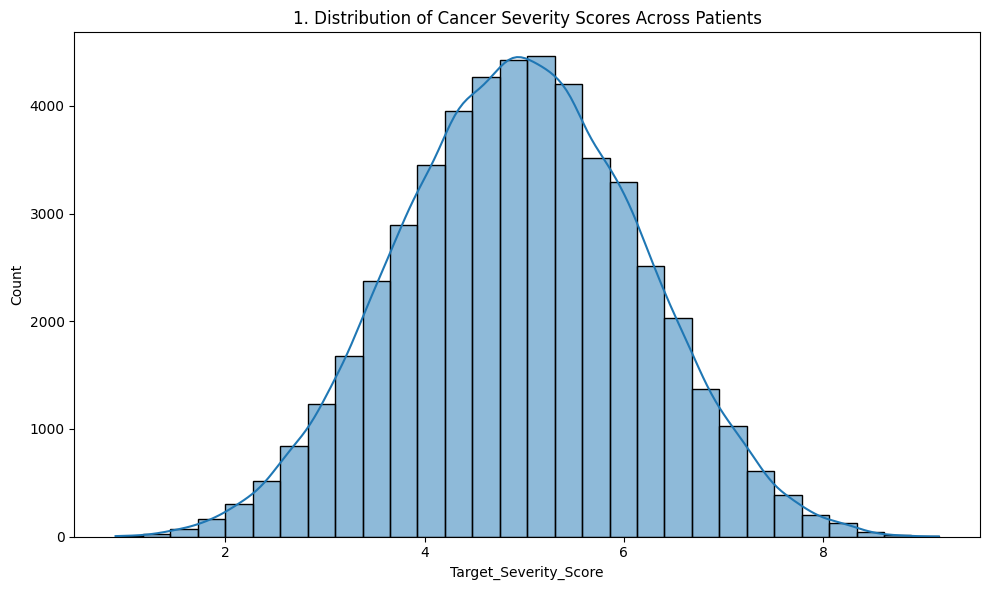

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Target_Severity_Score', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Cancer Severity Scores Across Patients')
show_fig()
plot_no += 1

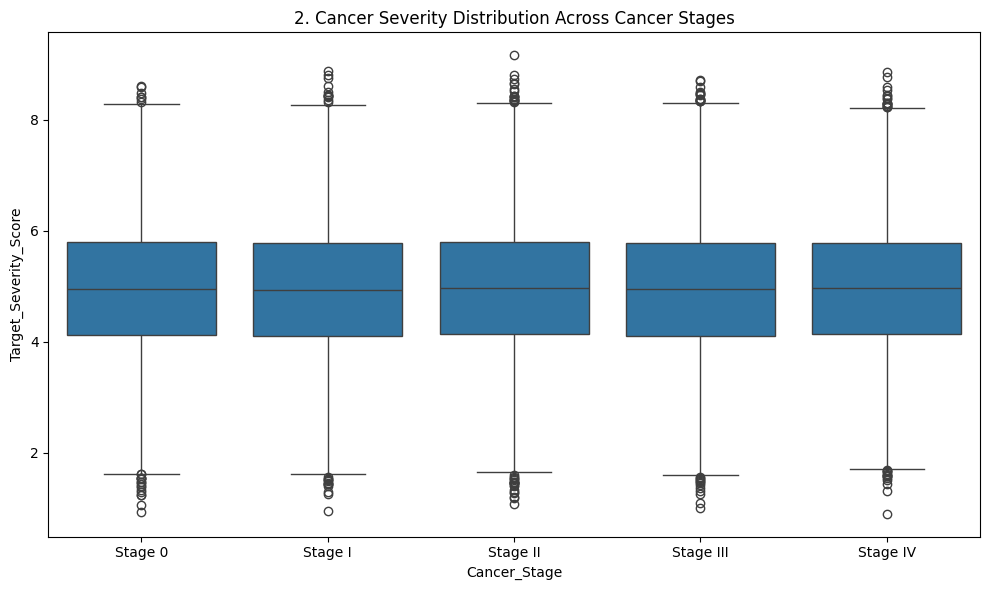

In [14]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Cancer_Stage', y='Target_Severity_Score', order=['Stage 0', 'Stage I', 'Stage II', 'Stage III', 'Stage IV'])
plt.title(f'{plot_no}. Cancer Severity Distribution Across Cancer Stages')
show_fig()
plot_no += 1

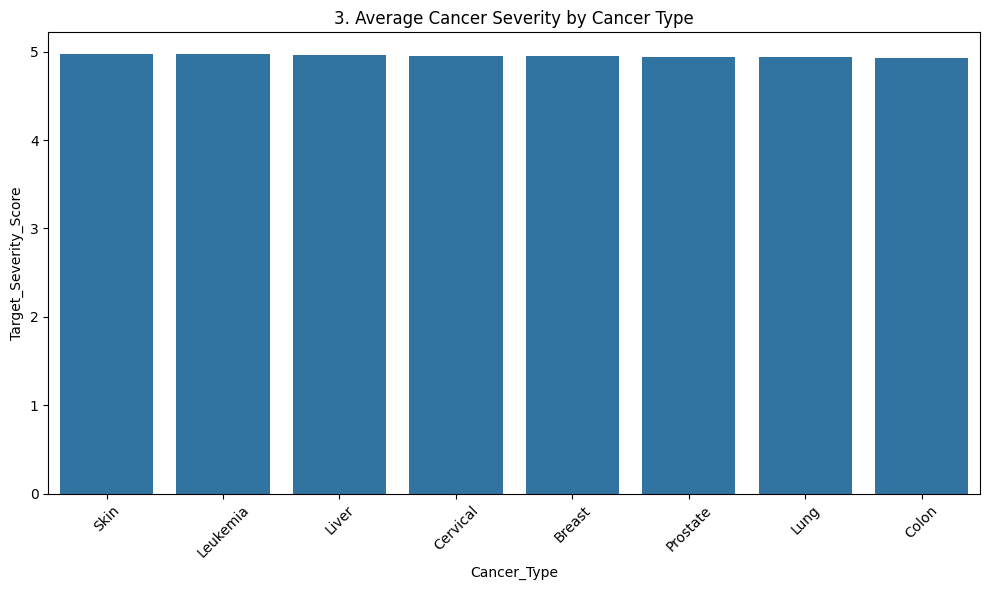

In [15]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Cancer_Type', y='Target_Severity_Score', estimator='mean', errorbar=None, order=df.groupby('Cancer_Type')['Target_Severity_Score'].mean().sort_values(ascending=False).index)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Average Cancer Severity by Cancer Type')
show_fig()
plot_no += 1

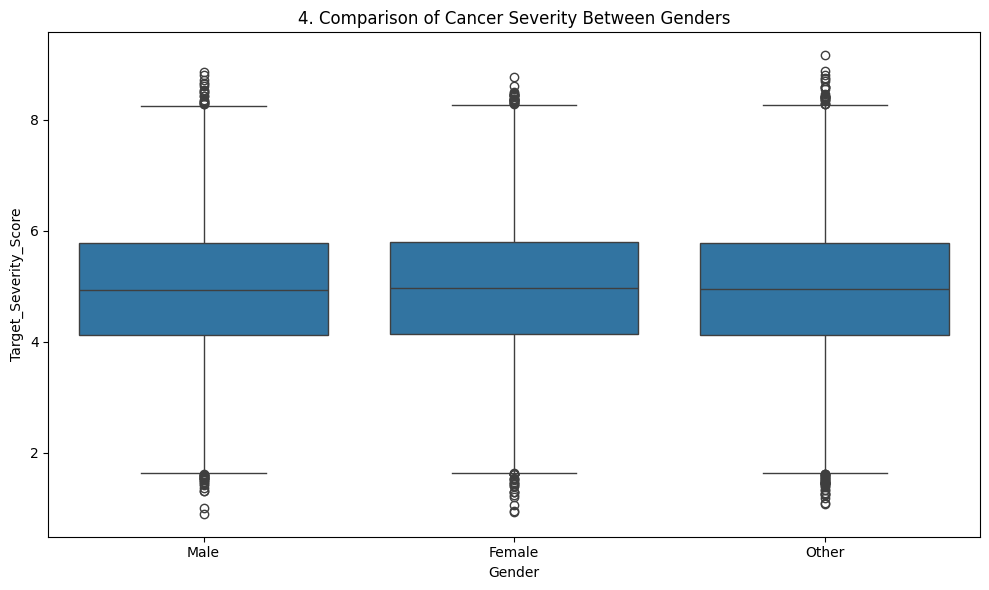

In [16]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Gender', y='Target_Severity_Score')
plt.title(f'{plot_no}. Comparison of Cancer Severity Between Genders')
show_fig()
plot_no += 1

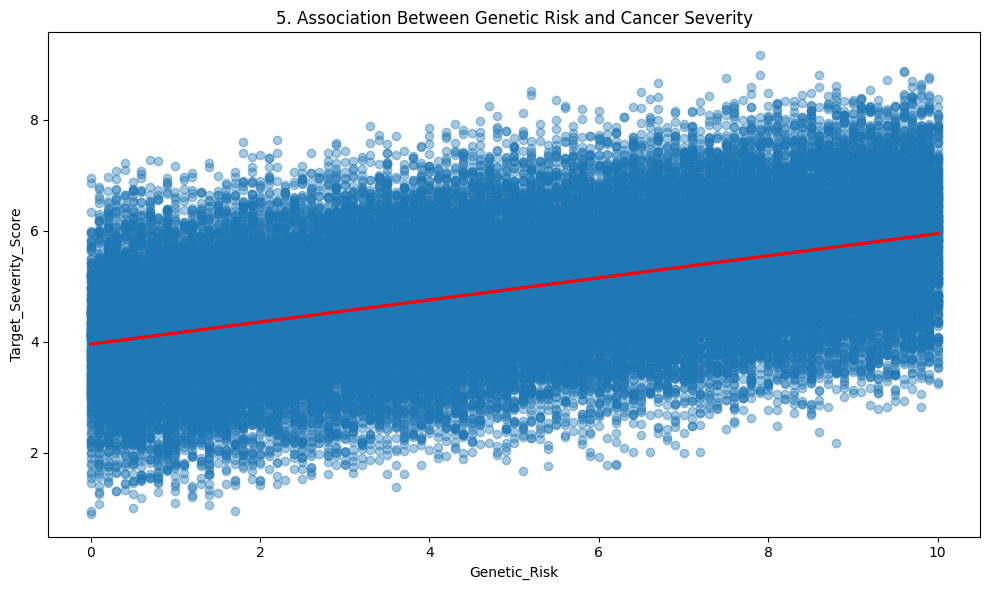

In [17]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Genetic_Risk', y='Target_Severity_Score', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Association Between Genetic Risk and Cancer Severity')
show_fig()
plot_no += 1

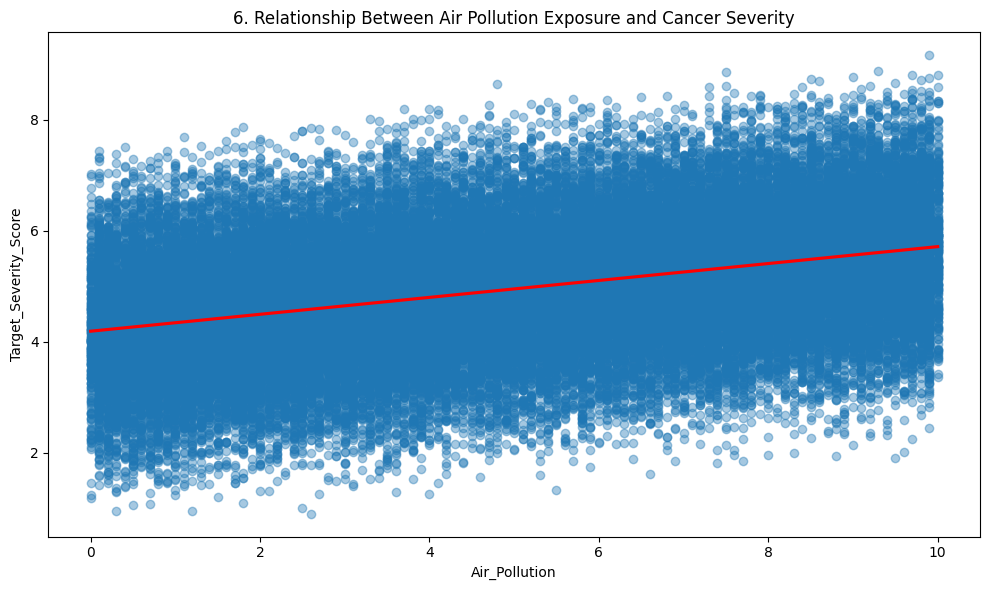

In [18]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Air_Pollution', y='Target_Severity_Score', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Relationship Between Air Pollution Exposure and Cancer Severity')
show_fig()
plot_no += 1

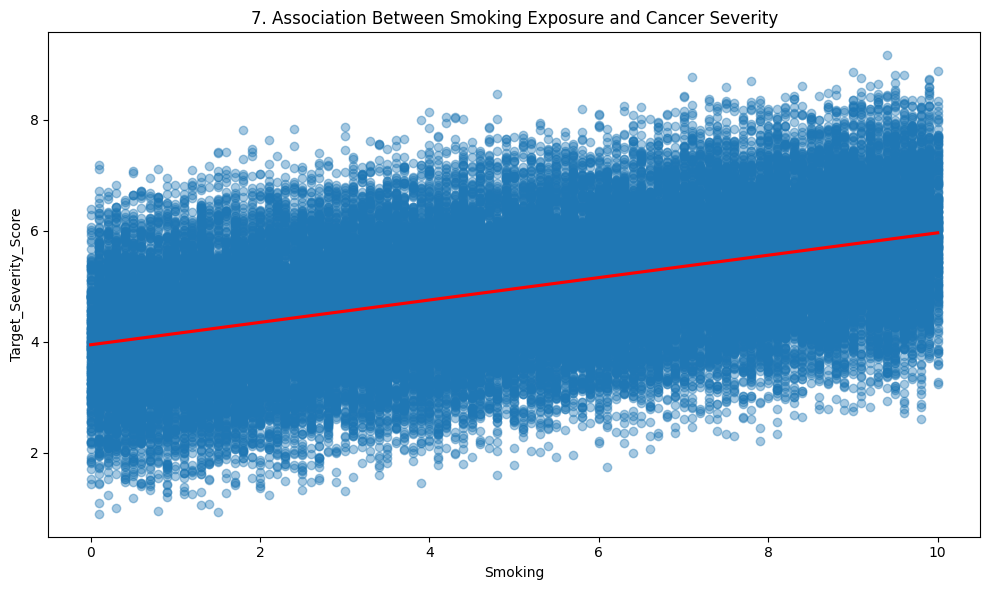

In [19]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Smoking', y='Target_Severity_Score', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Association Between Smoking Exposure and Cancer Severity')
show_fig()
plot_no += 1

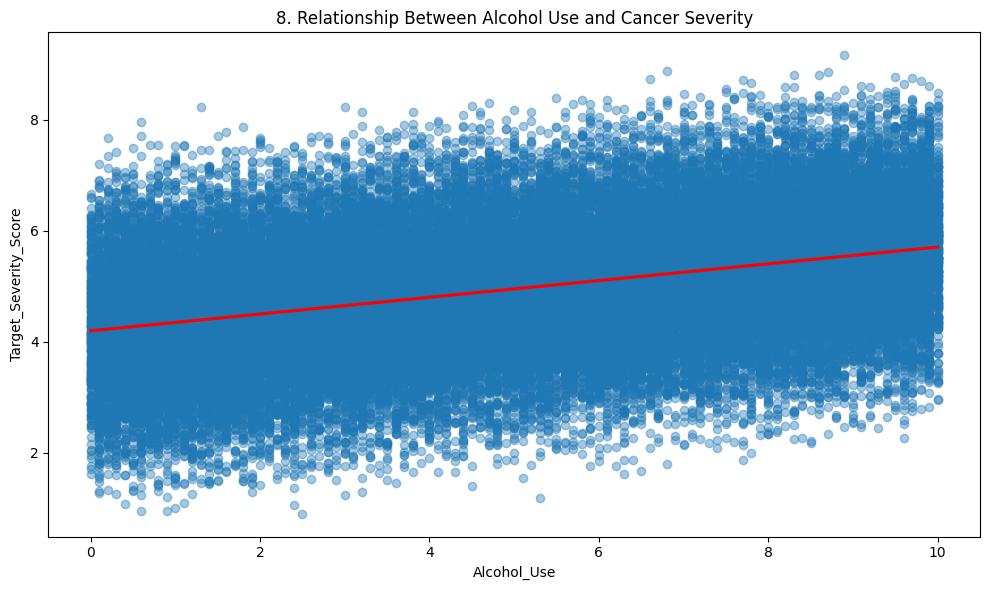

In [20]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Alcohol_Use', y='Target_Severity_Score', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Relationship Between Alcohol Use and Cancer Severity')
show_fig()
plot_no += 1

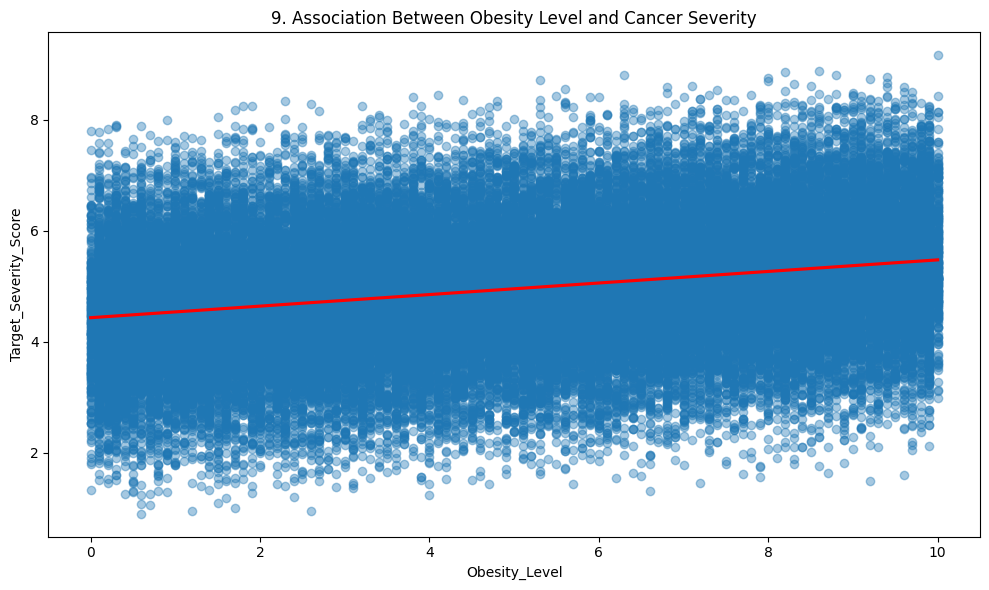

In [21]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Obesity_Level', y='Target_Severity_Score', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Association Between Obesity Level and Cancer Severity')
show_fig()
plot_no += 1

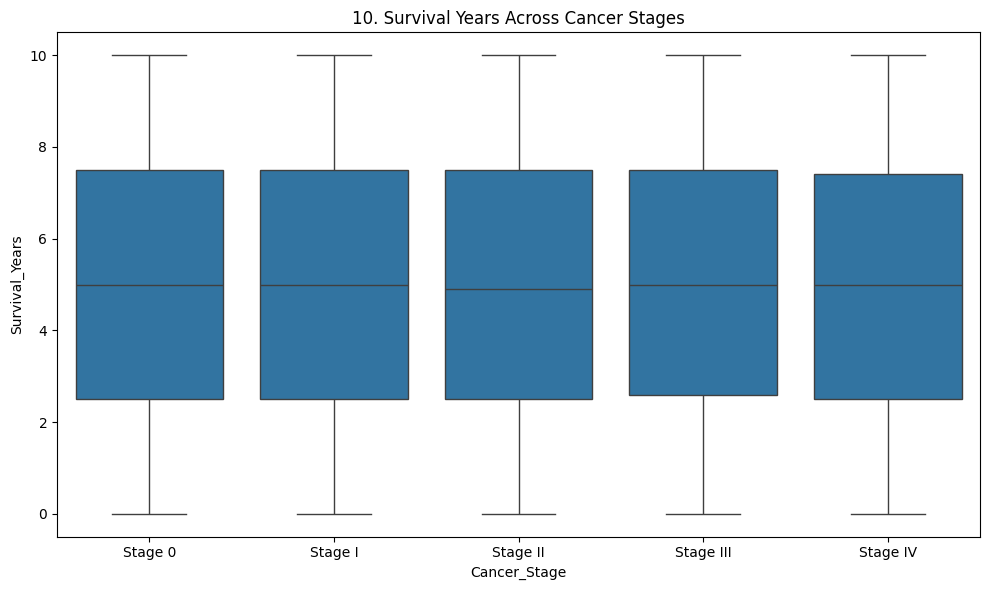

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Cancer_Stage', y='Survival_Years', order=['Stage 0', 'Stage I', 'Stage II', 'Stage III', 'Stage IV'])
plt.title(f'{plot_no}. Survival Years Across Cancer Stages')
show_fig()
plot_no += 1

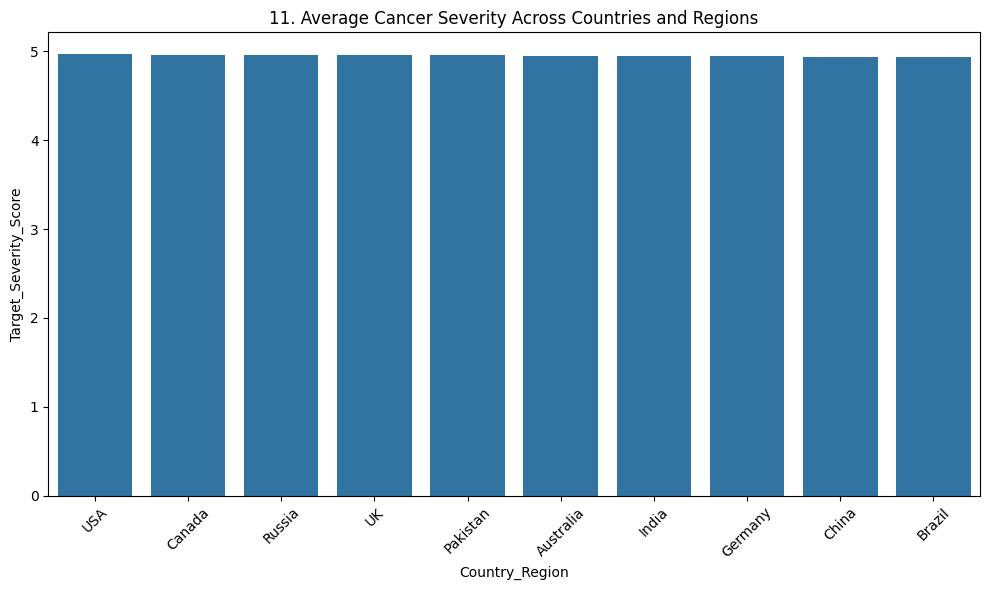

In [23]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Country_Region', y='Target_Severity_Score', estimator='mean', errorbar=None, order=df.groupby('Country_Region')['Target_Severity_Score'].mean().sort_values(ascending=False).index)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Average Cancer Severity Across Countries and Regions')
show_fig()
plot_no += 1

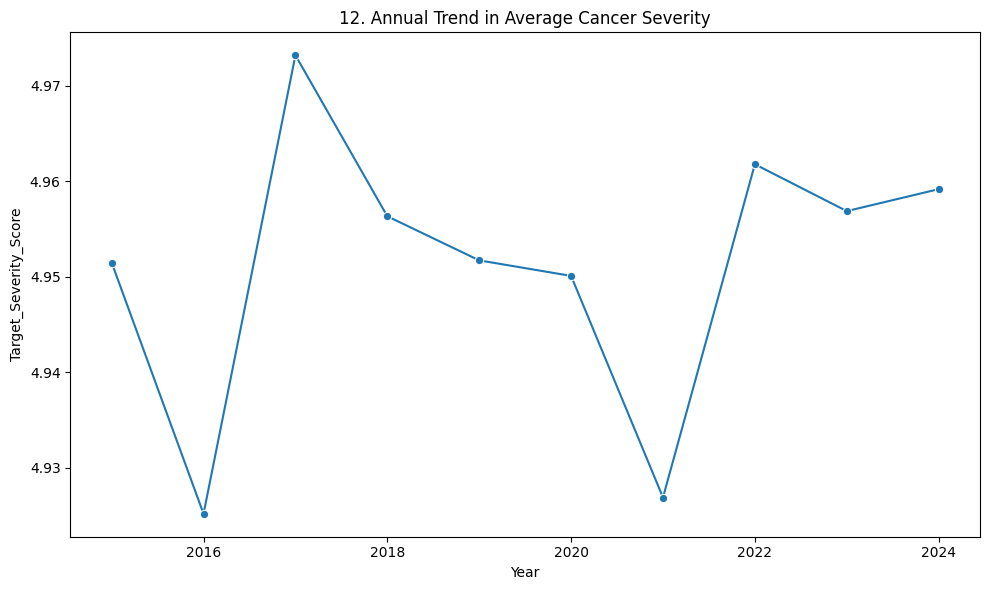

In [24]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='Year', y='Target_Severity_Score', estimator='mean', errorbar=None, marker='o')
plt.title(f'{plot_no}. Annual Trend in Average Cancer Severity')
show_fig()
plot_no += 1

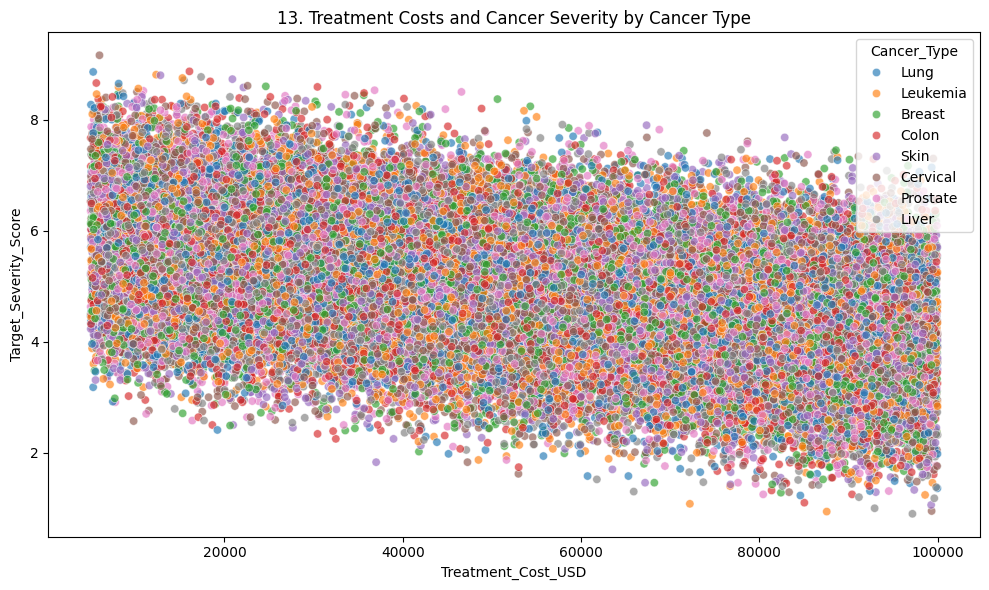

In [25]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Treatment_Cost_USD', y='Target_Severity_Score', hue='Cancer_Type', alpha=0.65)
plt.title(f'{plot_no}. Treatment Costs and Cancer Severity by Cancer Type')
show_fig()
plot_no += 1

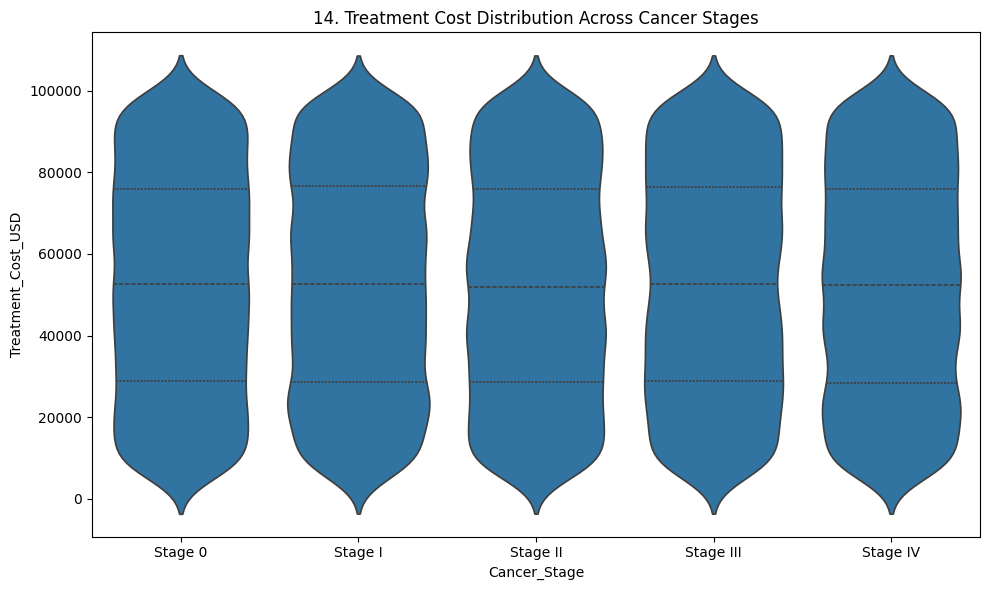

In [26]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='Cancer_Stage', y='Treatment_Cost_USD', order=['Stage 0', 'Stage I', 'Stage II', 'Stage III', 'Stage IV'], inner='quartile')
plt.title(f'{plot_no}. Treatment Cost Distribution Across Cancer Stages')
show_fig()
plot_no += 1

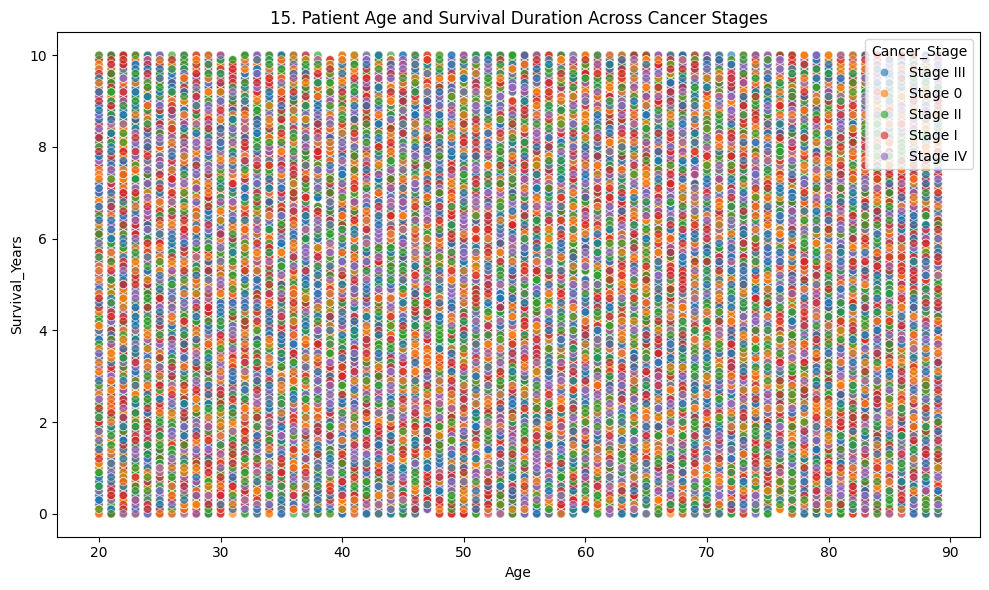

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Age', y='Survival_Years', hue='Cancer_Stage', alpha=0.65)
plt.title(f'{plot_no}. Patient Age and Survival Duration Across Cancer Stages')
show_fig()
plot_no += 1

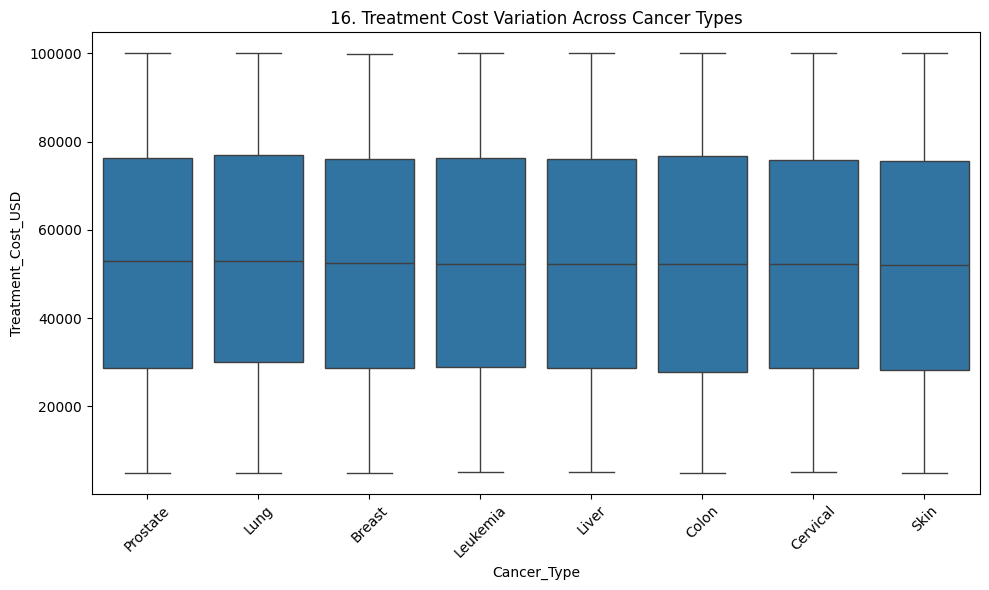

In [28]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Cancer_Type', y='Treatment_Cost_USD', order=df.groupby('Cancer_Type')['Treatment_Cost_USD'].median().sort_values(ascending=False).index)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Treatment Cost Variation Across Cancer Types')
show_fig()
plot_no += 1

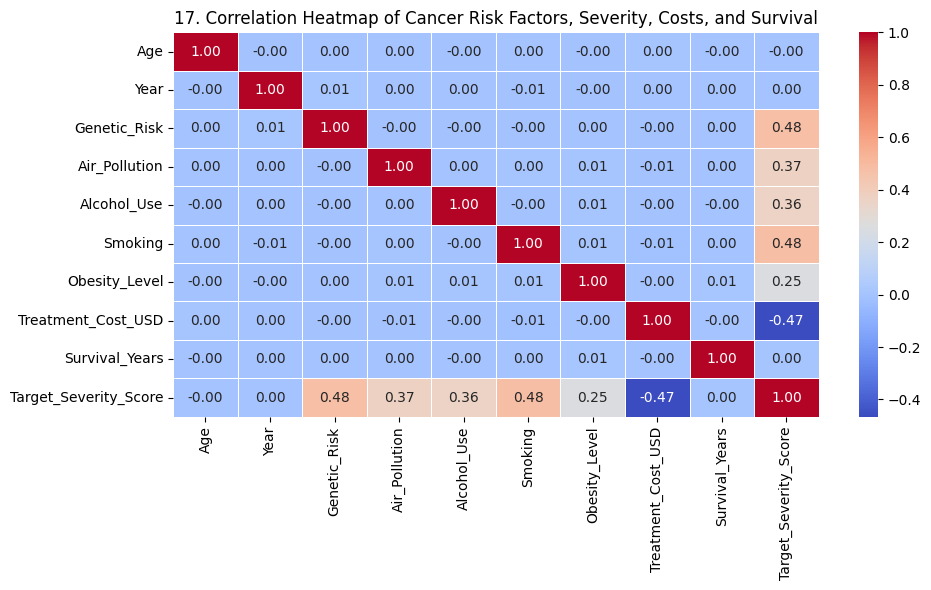

In [29]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').drop(columns=['Patient_ID'], errors='ignore').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Cancer Risk Factors, Severity, Costs, and Survival')
show_fig()
plot_no += 1

# Model Training

## Prepare features and target

In [30]:
data = df.drop(columns=['Patient_ID'], errors='ignore').copy()
X = data.drop(columns=['Target_Severity_Score'])
y = pd.to_numeric(data['Target_Severity_Score'], errors='coerce')
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

## Identify numerical and categorical features

In [31]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

## Build preprocessing pipelines

In [32]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Split the dataset

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Train the regression model

In [34]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=2,
        max_features=1.0, n_jobs=-1, random_state=42
    ))
])
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Predict test values

In [35]:
y_pred = model.predict(X_test)

## Evaluate model performance

In [36]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f'R² Score: {r2:.4f}')
print(f'Accuracy-style score (R² × 100): {r2 * 100:.2f}%')
print(f'MAE: {mae:.4f}')
print(f'RMSE: {rmse:.4f}')

R² Score: 0.9866
Accuracy-style score (R² × 100): 98.66%
MAE: 0.1063
RMSE: 0.1381


## Plot actual versus predicted values

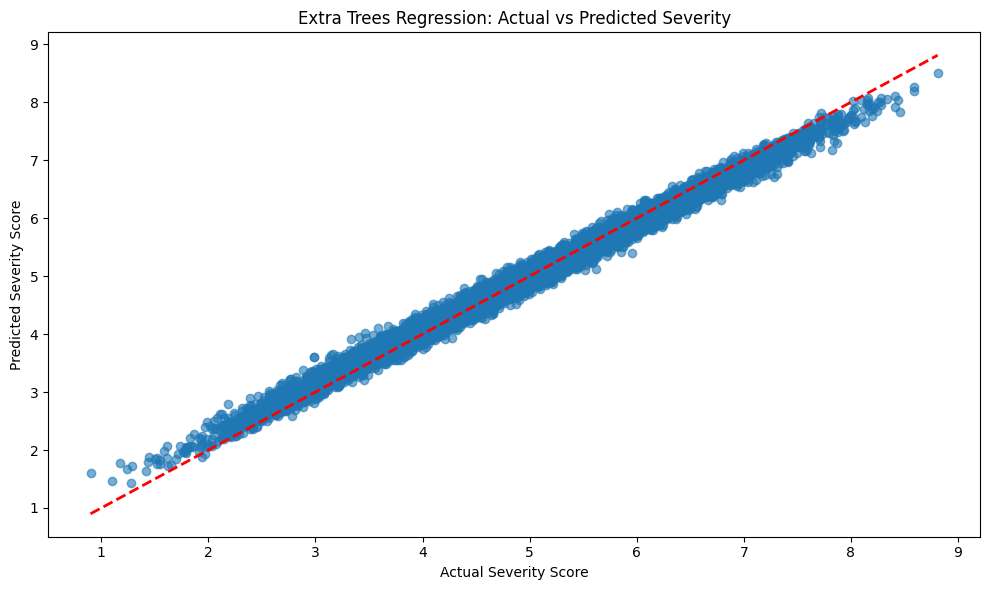

In [37]:
fig = plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], 'r--', linewidth=2)
plt.xlabel('Actual Severity Score')
plt.ylabel('Predicted Severity Score')
plt.title('Extra Trees Regression: Actual vs Predicted Severity')
plt.tight_layout()
plt.show()